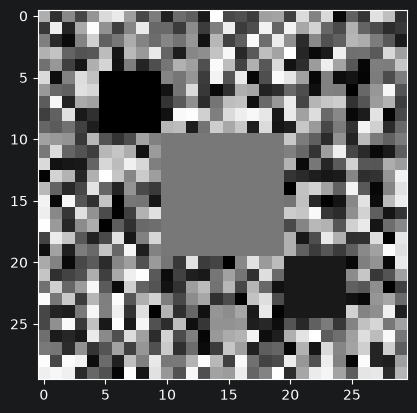

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Syntetyczny obraz z szumu
img = np.random.choice(256, size=(30,30))
img[5:10, 5:10] = 0
img[10:20, 10:20] = 120
img[20:25, 20:25] = 25

plt.imshow(img, cmap='binary_r')

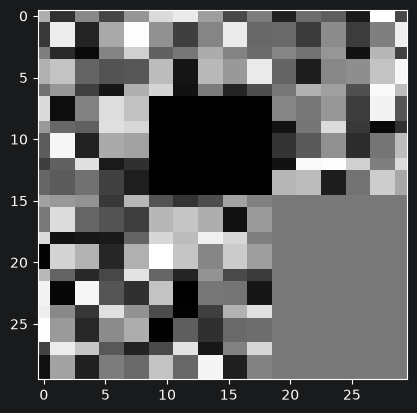

In [4]:
from skimage.transform import AffineTransform, warp

# Przykład przekształcenia geometrycznego
t = np.array(
    [[2.0, 0,   0],
     [0,   1.5, 0],
     [0,   0,   1]])

transform = AffineTransform(matrix = t)
transformed_img = warp(img, transform.inverse, order=0)

plt.imshow(transformed_img, cmap='binary_r')

In [5]:
# Weźmiemy sobie jeden wiersz, bo przykład będzie jedowymiarowy
signal = transformed_img[12]
signal

array([ 63,  97,  97, 224, 224,  26,  26,  49,  49,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,  17,  17, 249, 249, 253, 253, 208,
       208, 127, 127, 219], dtype=int32)

In [6]:
# Próbki oryginalne i nowe
original_space = np.linspace(0, 99, transformed_img.shape[1])
new_space = np.arange(0, 100)

print(original_space)
print(new_space)

[ 0.          3.4137931   6.82758621 10.24137931 13.65517241 17.06896552
 20.48275862 23.89655172 27.31034483 30.72413793 34.13793103 37.55172414
 40.96551724 44.37931034 47.79310345 51.20689655 54.62068966 58.03448276
 61.44827586 64.86206897 68.27586207 71.68965517 75.10344828 78.51724138
 81.93103448 85.34482759 88.75862069 92.17241379 95.5862069  99.        ]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]


In [7]:
# Odległość każdej próbki nowej siatki do oryginalej siatki
d = np.abs(new_space-original_space[:,np.newaxis])
print(d.shape)

print(d[1])
print(d[1].shape)

(30, 100)
[ 3.4137931  2.4137931  1.4137931  0.4137931  0.5862069  1.5862069
  2.5862069  3.5862069  4.5862069  5.5862069  6.5862069  7.5862069
  8.5862069  9.5862069 10.5862069 11.5862069 12.5862069 13.5862069
 14.5862069 15.5862069 16.5862069 17.5862069 18.5862069 19.5862069
 20.5862069 21.5862069 22.5862069 23.5862069 24.5862069 25.5862069
 26.5862069 27.5862069 28.5862069 29.5862069 30.5862069 31.5862069
 32.5862069 33.5862069 34.5862069 35.5862069 36.5862069 37.5862069
 38.5862069 39.5862069 40.5862069 41.5862069 42.5862069 43.5862069
 44.5862069 45.5862069 46.5862069 47.5862069 48.5862069 49.5862069
 50.5862069 51.5862069 52.5862069 53.5862069 54.5862069 55.5862069
 56.5862069 57.5862069 58.5862069 59.5862069 60.5862069 61.5862069
 62.5862069 63.5862069 64.5862069 65.5862069 66.5862069 67.5862069
 68.5862069 69.5862069 70.5862069 71.5862069 72.5862069 73.5862069
 74.5862069 75.5862069 76.5862069 77.5862069 78.5862069 79.5862069
 80.5862069 81.5862069 82.5862069 83.5862069 84.5862

In [8]:
# Najbliższy sąsiad
min_d = np.argmin(d, axis=0)
print(min_d)

[ 0  0  1  1  1  1  2  2  2  3  3  3  4  4  4  4  5  5  5  6  6  6  6  7
  7  7  8  8  8  8  9  9  9 10 10 10 11 11 11 11 12 12 12 13 13 13 13 14
 14 14 15 15 15 16 16 16 16 17 17 17 18 18 18 18 19 19 19 20 20 20 21 21
 21 21 22 22 22 23 23 23 23 24 24 24 25 25 25 25 26 26 26 27 27 27 28 28
 28 28 29 29]


In [9]:
# Wartości najbliższego sąsiada
new_signal = signal[min_d]
print(new_signal)

[ 63  63  97  97  97  97  97  97  97 224 224 224 224 224 224 224  26  26
  26  26  26  26  26  49  49  49  49  49  49  49   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0  17  17  17  17  17  17 249 249
 249 249 249 249 249 253 253 253 253 253 253 253 208 208 208 208 208 208
 208 127 127 127 127 127 127 127 219 219]


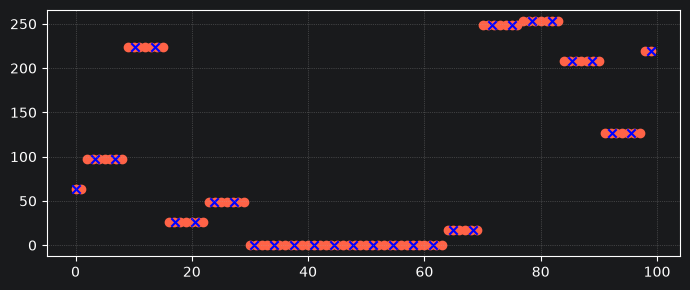

In [10]:
fig, ax = plt.subplots(1,1,figsize=(7,3))
plt.scatter(new_space, new_signal, color='tomato')
plt.scatter(original_space, signal, marker='x', color='b')
plt.grid(ls=':')

plt.tight_layout()

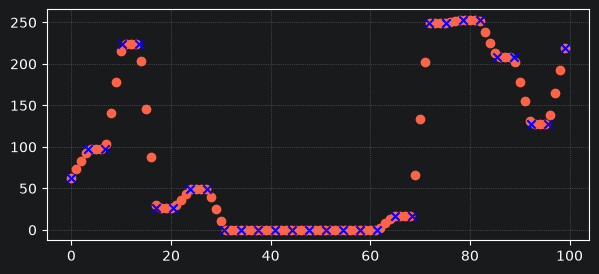

In [11]:
# Uwaga, interpolacja liniowa
new_signal = []

for n_s in new_space:
    
    # Szukanie najbliższych sąsiadów po prawej i lewej
    d = original_space - n_s

    if np.min(np.abs(d)) == 0:
        new_signal.append(signal[np.argmin(np.abs(d))])
    else:
        d_left = np.copy(d)
        d_left[d>0] = np.inf
        d_right = np.copy(d)
        d_right[d<0] = np.inf

        # Równanie prostej
        a = original_space[np.argmin(np.abs(d_left))]
        b = signal[np.argmin(np.abs(d_left))]
        
        c = original_space[np.argmin(np.abs(d_right))]
        d = signal[np.argmin(np.abs(d_right))]
        
        # n i k to parametry funkcji liniowej
        n = (b*c - d*a)/(c-a)
        k = (d-n)/c
        
        # Określenie wartości w punkcie n_s
        y = (k*n_s) + n
        new_signal.append(y)

fig, ax = plt.subplots(1,1,figsize=(7,3))
ax.scatter(new_space, new_signal, color='tomato')
plt.scatter(original_space, signal, marker='x', color='b')
ax.grid(ls=':')
